#  Load dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

In [5]:
df = pd.read_csv("311_Service_Requests_(July_2008_-__May_2024)_20251007.csv", low_memory=False)

In [7]:
df = df[['Status', 'Subject', 'Reason', 'Type', 'Neighborhood']].dropna()

In [9]:
df['Status'] = (df['Status'] == "Closed").astype(int)

In [11]:
for col in ['Subject', 'Reason', 'Type', 'Neighborhood']:
    df[col] = df[col].astype('category').cat.codes

In [13]:
X = df[['Subject', 'Reason', 'Type', 'Neighborhood']].values
y = df['Status'].values.reshape(-1,1)

In [15]:
split = int(0.8 * len(X))
X_train, X_test = X[:split], X[split:]
y_train, y_test = y[:split], y[split:]

In [17]:
X_mean, X_std = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - X_mean) / (X_std + 1e-8)
X_test = (X_test - X_mean) / (X_std + 1e-8)

# Logistic Regression (manual implementation)

In [19]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))
def logistic_regression_train(X, y, lr=0.01, epochs=200):
    N, d = X.shape
    W = np.zeros((d,1))
    b = 0
    for ep in range(epochs):
        z = X @ W + b
        y_hat = sigmoid(z)
        error = y_hat - y
        grad_W = (X.T @ error) / N
        grad_b = np.mean(error)
        
        # update step
        W -= lr * grad_W
        b -= lr * grad_b
        
        if ep % 50 == 0:
            loss = -np.mean(y*np.log(y_hat+1e-8) + (1-y)*np.log(1-y_hat+1e-8))
            print(f"Epoch {ep}: Loss={loss:.4f}")
    
    return W, b
def predict(X, W, b):
    return (sigmoid(X @ W + b) >= 0.5).astype(int)
W, b = logistic_regression_train(X_train, y_train, lr=0.1, epochs=500)
y_pred = predict(X_test, W, b)
#Here we train the model using logistic regression 

Epoch 0: Loss=0.6931
Epoch 50: Loss=0.2142
Epoch 100: Loss=0.1263
Epoch 150: Loss=0.0940
Epoch 200: Loss=0.0779
Epoch 250: Loss=0.0685
Epoch 300: Loss=0.0625
Epoch 350: Loss=0.0583
Epoch 400: Loss=0.0553
Epoch 450: Loss=0.0530


# Evaluation

In [23]:
#here we got accuracy 1 because it got overfitted or the model works fine because of the preprocessing done properly  
accuracy = np.mean(y_pred == y_test)
print("Test Accuracy:", accuracy)
conf_matrix = pd.crosstab(y_test.flatten(), y_pred.flatten(),
                          rownames=['Actual'], colnames=['Predicted'])
print(conf_matrix)

Test Accuracy: 1.0
Predicted       1
Actual           
1          225855


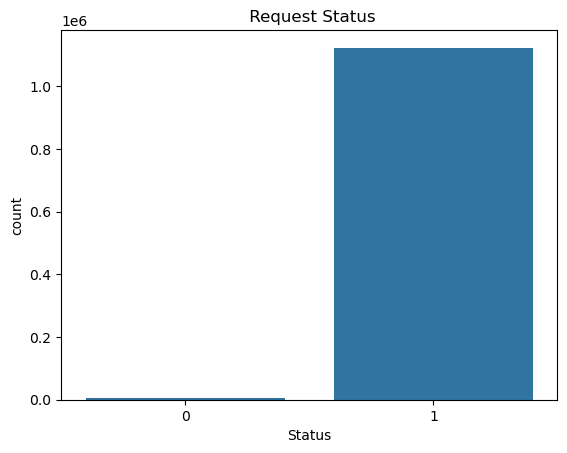

In [25]:
sns.countplot(x=df['Status'])
plt.title(" Request Status")
plt.show()

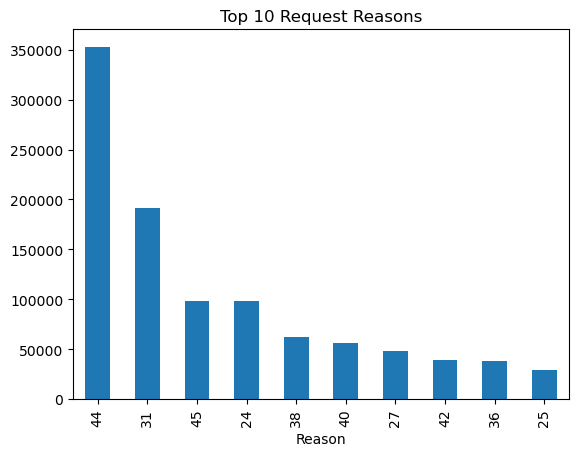

In [27]:
df['Reason'].value_counts().head(10).plot(kind='bar')
plt.title("Top 10 Request Reasons")
plt.show()

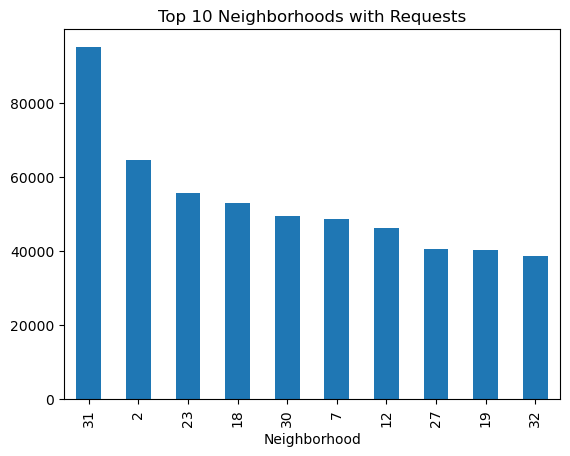

In [29]:
df['Neighborhood'].value_counts().head(10).plot(kind='bar')
plt.title("Top 10 Neighborhoods with Requests")
plt.show()

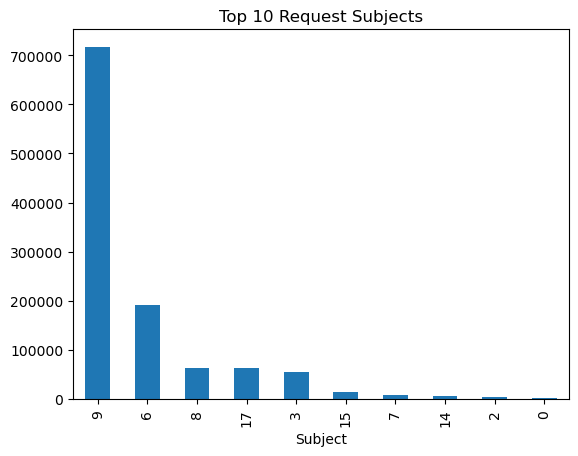

In [31]:
df['Subject'].value_counts().head(10).plot(kind='bar')
plt.title("Top 10 Request Subjects")
plt.show()

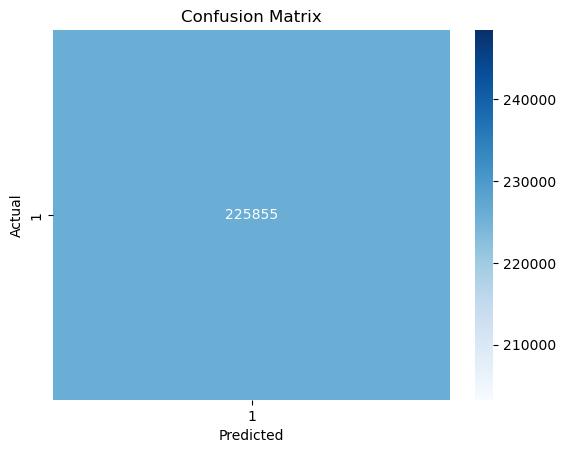

In [35]:
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

In [37]:
df.to_csv("buffalo_cleaned.csv", index=False)
with open("a1_bonus_1_weights_odrabira_pranayla.pkl", "wb") as f:
    pickle.dump((W, b), f)

In [ ]:
#REFERENCES:
https://towardsdatascience.com/logistic-regression-from-scratch-in-python-ec66603592e2/
https://pandas.pydata.org
https://numpy.org
https://elcaiseri.medium.com/building-a-simple-logistic-regression-model-from-scratch-with-numpy-c8cf2439d059
https://www.geeksforgeeks.org/machine-learning/understanding-logistic-regression/

| Team Member | Assignment part | Contribution |
|----------|----------|----------|
| Odra Bira | bonus 1 | 50% |
| Pranay Lachuluri | bonus 1 | 50% |

